# Module 06 · Bộ lọc tích cực (Floyd chương 15)

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
db = lambda x: 20*np.log10(np.abs(x))

## 1. Tần số tới hạn và băng thông

In [2]:
fc = 1/(2*np.pi*2.2e3*0.0015e-6); print(f"Prob 3: fc = {fc/1e3:.1f} kHz")
f1, f2 = 3.2e3, 3.9e3; f0 = np.sqrt(f1*f2); print(f"Prob 5: BW = {f2-f1:.0f} Hz, f0 = {f0:.0f} Hz, Q = {f0/(f2-f1):.2f}")
print("Prob 6: f0 =", 15*1e3, "Hz")

Prob 3: fc = 48.2 kHz
Prob 5: BW = 700 Hz, f0 = 3533 Hz, Q = 5.05
Prob 6: f0 = 15000.0 Hz


**Nhận xét:** fc = 48.2 kHz đúng sách (48,2 kHz); BW = 700 Hz; Q = 5,05 (sách in 5,04).

## 2. Butterworth, Chebyshev (1 dB), Bessel bậc 2

Butterworth     gain at 3 kHz = -19.14 dB, gain variation below 500 Hz = 0.25 dB, gain at 1 kHz = -3.01 dB
Chebyshev 1 dB  gain at 3 kHz = -18.80 dB, gain variation below 500 Hz = 0.68 dB, gain at 1 kHz = -1.00 dB
Bessel          gain at 3 kHz = -15.74 dB, gain variation below 500 Hz = 0.67 dB, gain at 1 kHz = -3.01 dB


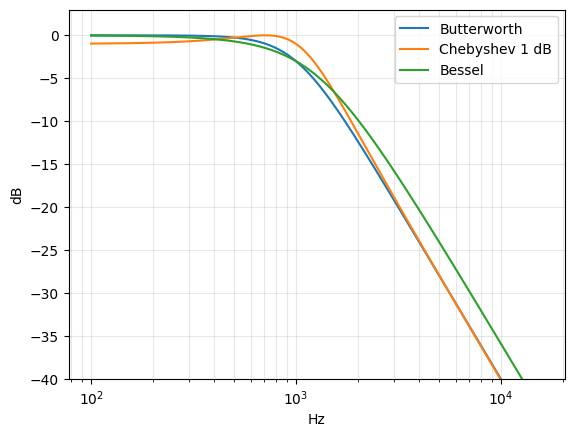

In [3]:
from scipy import signal
f = np.logspace(2, 4.2, 400); w = 2*np.pi*f; wc = 2*np.pi*1e3
for name, (b, a) in {"Butterworth": signal.butter(2, wc, analog=True), "Chebyshev 1 dB": signal.cheby1(2, 1, wc, analog=True), "Bessel": signal.bessel(2, wc, analog=True, norm="mag")}.items():
    _, h = signal.freqs(b, a, w); plt.semilogx(f, db(h), label=name)
    print(f"{name:15s} gain at 3 kHz = {db(signal.freqs(b,a,[2*np.pi*3e3])[1][0]):6.2f} dB, gain variation below 500 Hz = {np.ptp(db(h[f<500])):.2f} dB, gain at 1 kHz = {db(signal.freqs(b,a,[2*np.pi*1e3])[1][0]):.2f} dB")
plt.ylim(-40, 3); plt.legend(); plt.grid(alpha=.3, which="both"); plt.xlabel("Hz"); plt.ylabel("dB"); plt.show()

**Nhận xét:** Tại 1 kHz Butterworth và Bessel đều −3,01 dB còn Chebyshev −1,00 dB vì thiết kế theo mép gợn 1 dB (tần số −3 dB của nó cao hơn 1 kHz). Tại 3 kHz suy giảm là −19,1 dB (Butterworth), −18,8 dB (Chebyshev) và −15,7 dB (Bessel): Bessel có độ suy giảm chậm nhất. Muốn thấy Chebyshev dốc hơn phải so sánh ở cùng tần số −3 dB.

## 3. Hệ số tắt dần và R1/R2

In [4]:
for n, dfs in {2: [1.414], 4: [1.848, 0.765], 6: [1.932, 1.414, 0.518]}.items():
    print(n, "poles:", [round(2-d, 3) for d in dfs])

2 poles: [0.586]
4 poles: [0.152, 1.235]
6 poles: [0.068, 0.586, 1.482]


**Nhận xét:** sáu cực cho 0,068; 0,586; 1,482 trùng đáp án Bài 13 của sách.

## 4. Thông dải hồi tiếp nhiều đường (Floyd Bài 19b)

f0 = 449 Hz, BW = 96.5 Hz, Q = 4.65


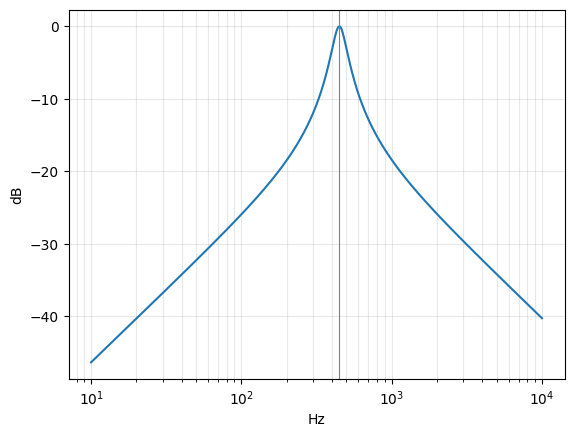

-3 dB band: 405 .. 499 Hz -> width 93 Hz


In [5]:
R1, R2, R3, C = 47e3, 150e3, 1.8e3, 0.022e-6
f0 = 1/(2*np.pi*C)*np.sqrt((R1+R3)/(R1*R2*R3)); BW = 1/(np.pi*R2*C)
print(f"f0 = {f0:.0f} Hz, BW = {BW:.1f} Hz, Q = {f0/BW:.2f}")
f = np.logspace(1, 4, 600); s = 2j*np.pi*f; w0 = 2*np.pi*f0; Q = f0/BW
H = (s*w0/Q)/(s**2 + s*w0/Q + w0**2); plt.semilogx(f, db(H)); plt.axvline(f0, color="gray", lw=.8); plt.grid(alpha=.3, which="both"); plt.xlabel("Hz"); plt.ylabel("dB"); plt.show()
idx = np.where(db(H) >= -3.01)[0]; print(f"-3 dB band: {f[idx[0]]:.0f} .. {f[idx[-1]]:.0f} Hz -> width {f[idx[-1]]-f[idx[0]]:.0f} Hz")

**Nhận xét:** f0 = 449 Hz, BW = 96,5 Hz (sách: 96,4 Hz); đồ thị mô hình bậc hai cho dải −3 dB rộng xấp xỉ BW.